In [185]:
base_path = "../HySpecNet/hyspecnet-11k/patches/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z-Y01460273_X03110438/ENMAP01-____L2A-DT0000004950_20221103T162438Z_001_V010110_20221118T145147Z-Y01460273_X03110438"

def get_file_extension(base_path):
    npy_file_path = f"{base_path}-DATA.npy"
    tif_file_path = f"{base_path}-SPECTRAL_IMAGE.TIF"

    return npy_file_path, tif_file_path

npy_file_path, tif_file_path = get_file_extension(base_path)

In [186]:
import rasterio

with rasterio.open(tif_file_path) as src:
    print(src.profile)

{'driver': 'GTiff', 'dtype': 'int16', 'nodata': -32768.0, 'width': 128, 'height': 128, 'count': 224, 'crs': CRS.from_epsg(32618), 'transform': Affine(30.0, 0.0, 688005.0,
       0.0, -30.0, 4561935.0), 'blockysize': 3, 'tiled': False, 'compress': 'deflate', 'interleave': 'band'}


Number of bands in .npy file: 202
Number of bands in .tif file: 128
The number of bands differs between the files.


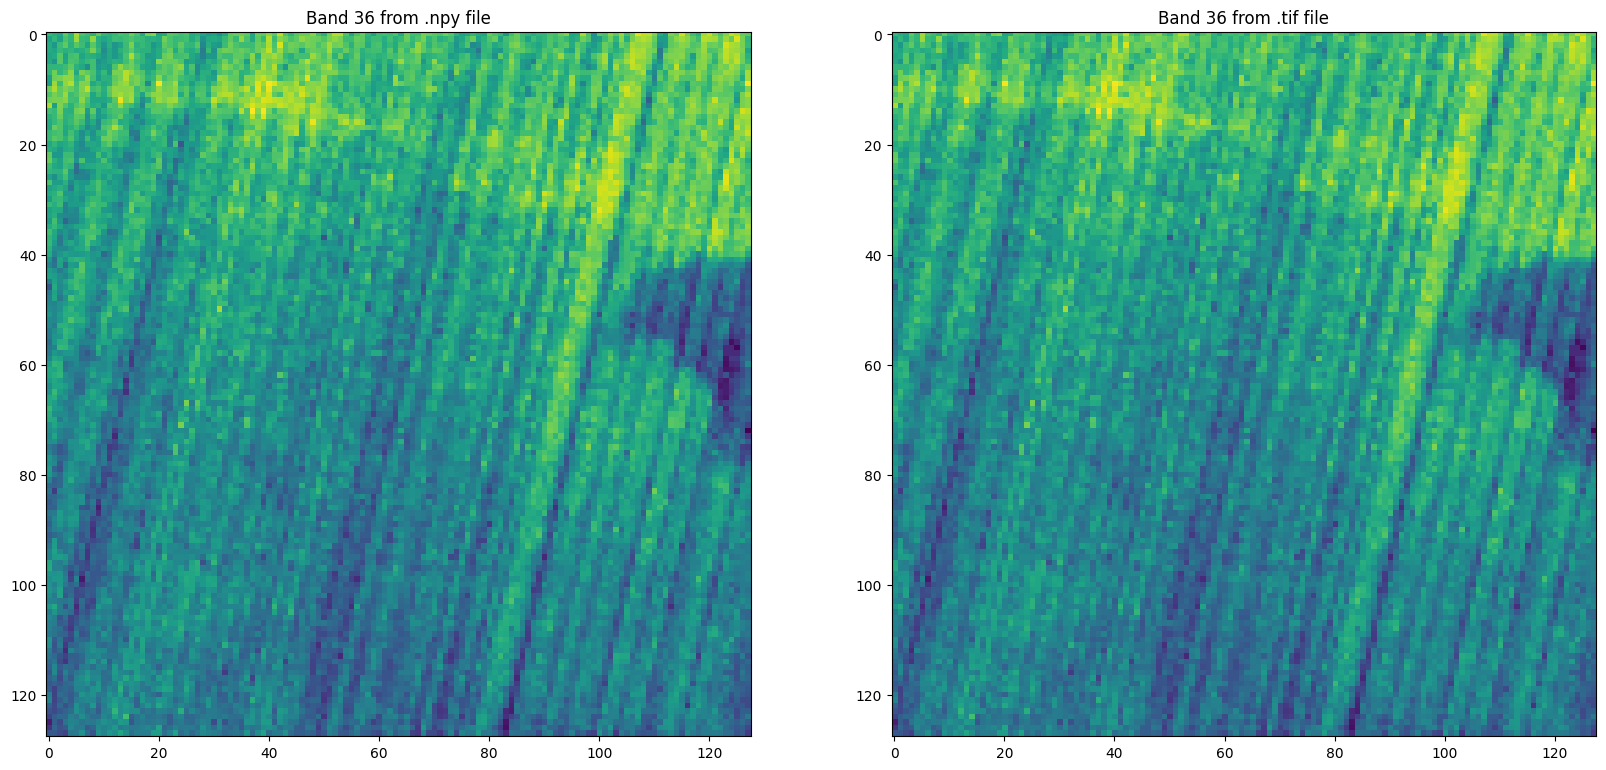

In [187]:
import numpy as np
import matplotlib.pyplot as plt

def load_and_compare_band(base_path, band_index=0):
    npy_file_path = f"{base_path}-DATA.npy"
    tif_file_path = f"{base_path}-SPECTRAL_IMAGE.TIF"
    
    # Load data from .npy file
    hsi_data_npy = np.load(npy_file_path)
    num_bands_npy = hsi_data_npy.shape[0]
    
    # Load data from .tif file
    with rasterio.open(tif_file_path) as src:
        hsi_data_tif = src.read()
        num_bands_tif = src.shape[0]


    print(f"Number of bands in .npy file: {num_bands_npy}")
    print(f"Number of bands in .tif file: {num_bands_tif}")

    # Verify if they have the same number of bands
    if num_bands_npy == num_bands_tif:
        print("Both files have the same number of bands.")
    else:
        print("The number of bands differs between the files.")

    band_npy = hsi_data_npy[band_index, :, :]
    band_tif = hsi_data_tif[band_index, :, :]

    # Compare the two bands
    fig, ax = plt.subplots(1, 2, figsize=(20, 10))
    ax[0].imshow(band_npy)
    ax[0].set_title(f"Band {band_index} from .npy file")
    ax[1].imshow(band_tif)
    ax[1].set_title(f"Band {band_index} from .tif file")

    plt.show()

load_and_compare_band(base_path, band_index=36)

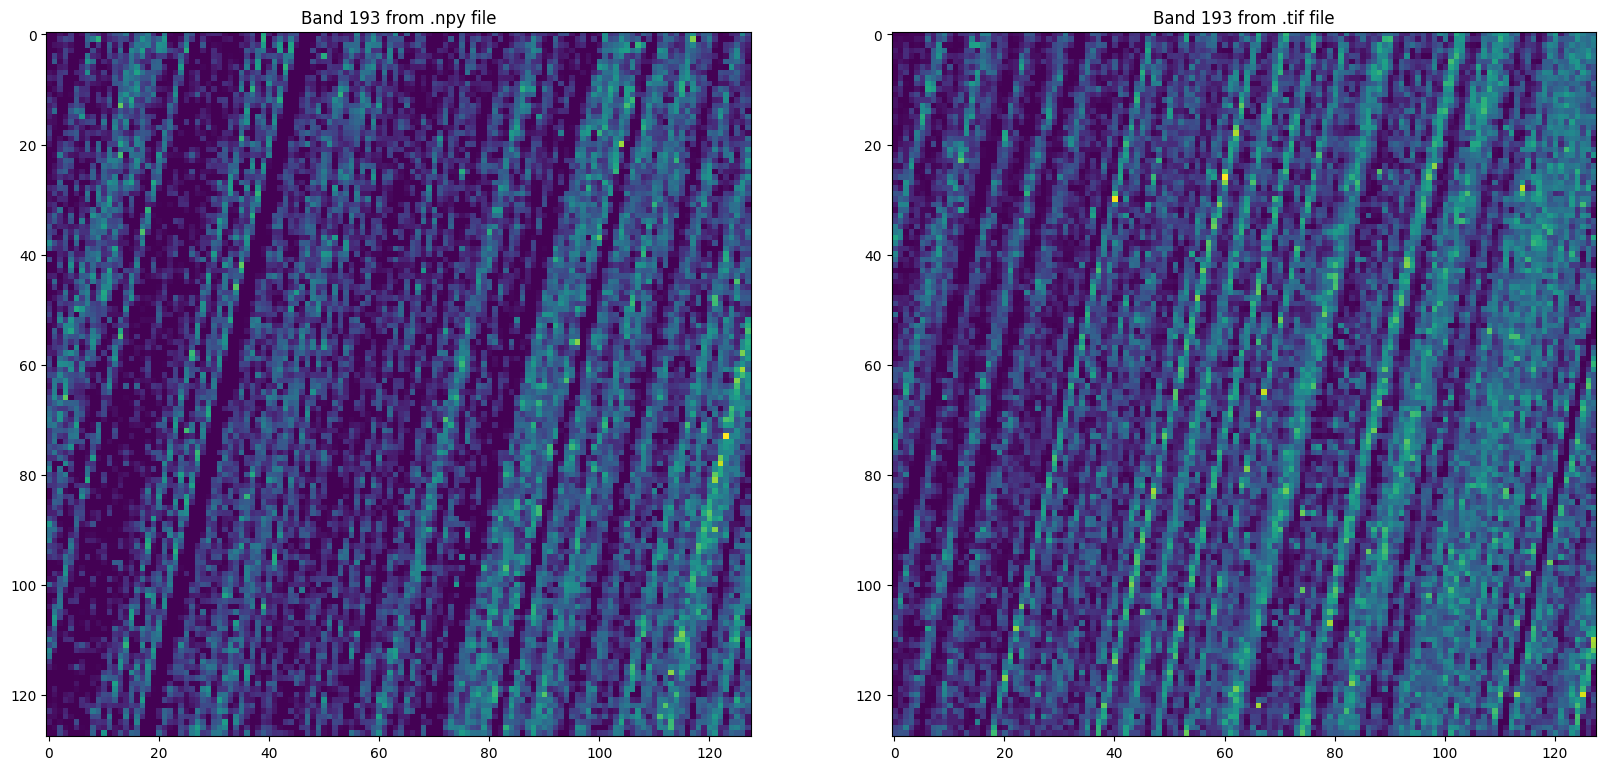

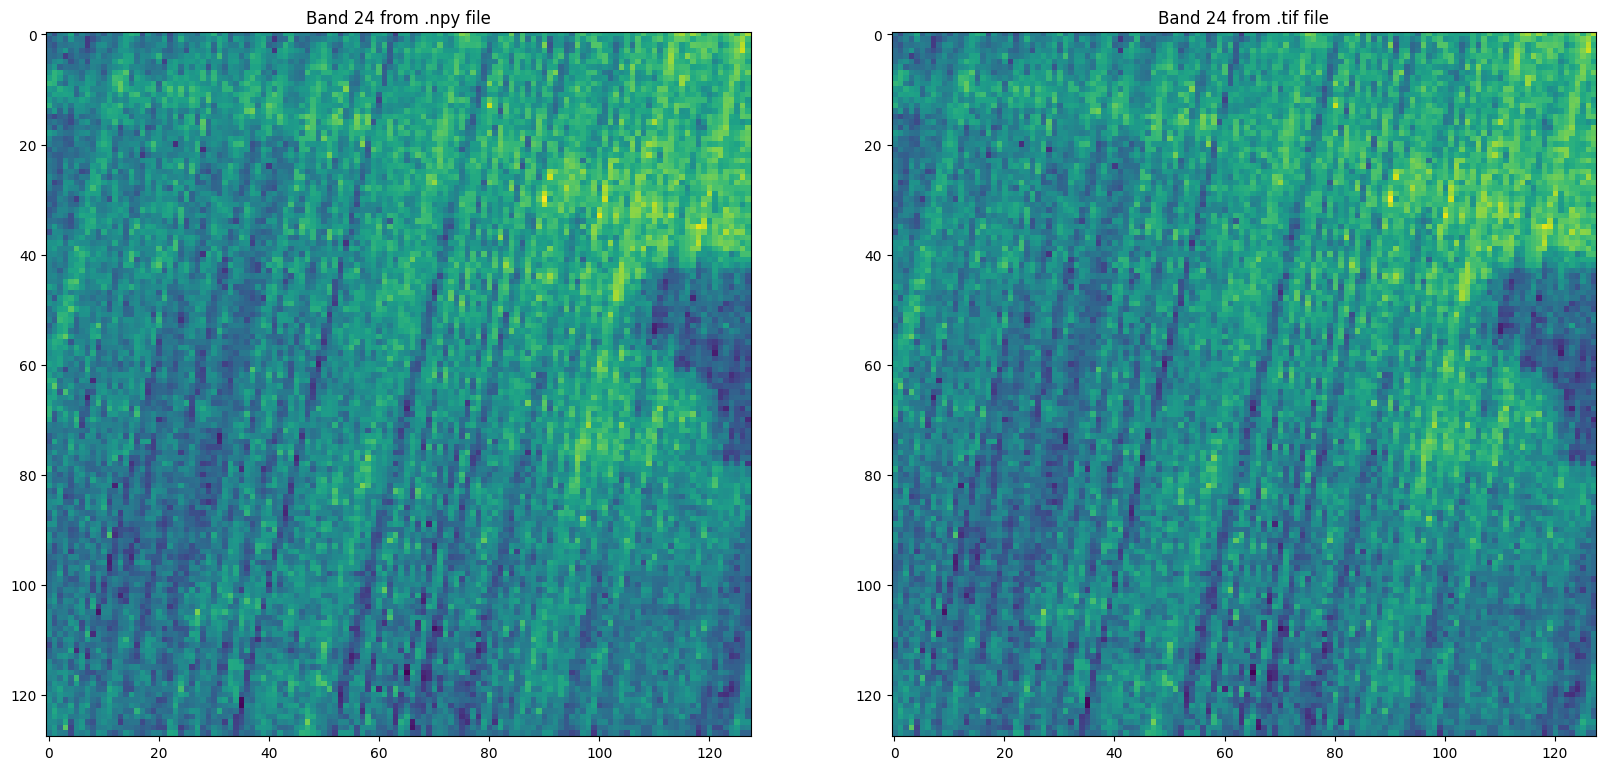

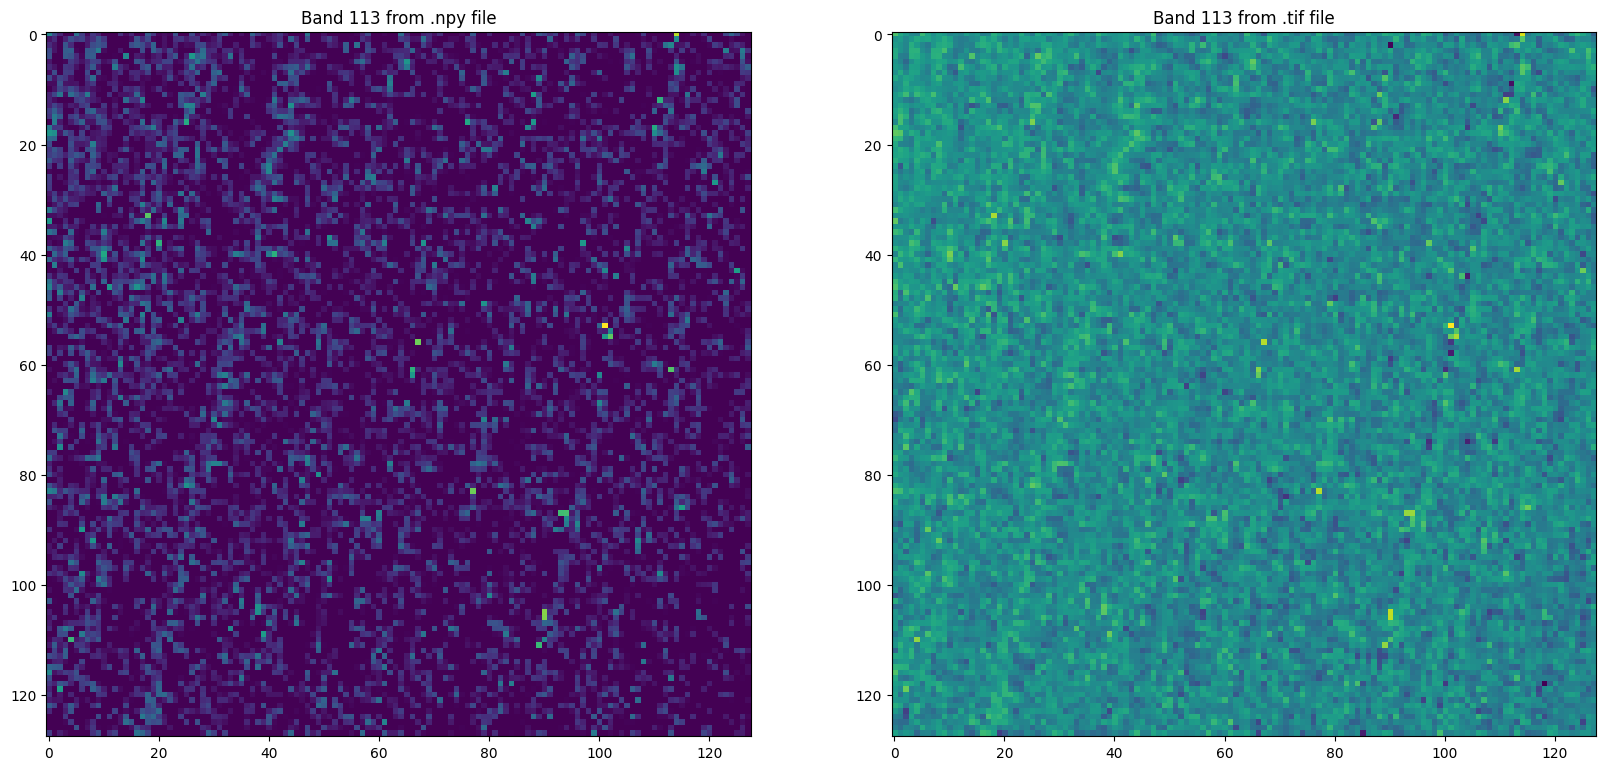

In [188]:
def load_and_compare_bands_random(base_path, num_bands=10):
    npy_file_path = f"{base_path}-DATA.npy"
    tif_file_path = f"{base_path}-SPECTRAL_IMAGE.TIF"
    
    # Load data from .npy file
    hsi_data_npy = np.load(npy_file_path)
    
    # Load data from .tif file
    with rasterio.open(tif_file_path) as src:
        hsi_data_tif = src.read()

    total_bands = hsi_data_npy.shape[0]
    band_indices = np.random.choice(total_bands, num_bands, replace=False)

    for band_index in band_indices:
        band_npy = hsi_data_npy[band_index, :, :]
        band_tif = hsi_data_tif[band_index, :, :]

        # Compare the two bands
        fig, ax = plt.subplots(1, 2, figsize=(20, 10))
        ax[0].imshow(band_npy)
        ax[0].set_title(f"Band {band_index} from .npy file")
        ax[1].imshow(band_tif)
        ax[1].set_title(f"Band {band_index} from .tif file")

        plt.show()

load_and_compare_bands_random(base_path, num_bands=3)

Create a lookup table for VNIR to SWIR bands. This will cover spectral ranges from 418.42 nm to 2,445.30 nm.

In [189]:
import pandas as pd

vnir_bands = pd.read_csv("../EnMAP/vnir_bands.csv")
swir_bands = pd.read_csv("../EnMAP/swir_bands.csv")

vnir_bands['Type'] = 'VNIR'
swir_bands['Type'] = 'SWIR'

swir_bands['BAND #'] += vnir_bands['BAND #'].max()

bands = pd.concat([vnir_bands, swir_bands], ignore_index=True)

bands.to_csv("enmap_bands.csv")

print(bands.head())
print(bands.tail())

bands = pd.read_csv("enmap_bands.csv")

   BAND #  CW (nm)  FWHM (nm)  Type
0       1   418.42       7.00  VNIR
1       2   424.04       6.67  VNIR
2       3   429.46       6.42  VNIR
3       4   434.69       6.25  VNIR
4       5   439.76       6.13  VNIR
     BAND #  CW (nm)  FWHM (nm)  Type
219     220  2415.21       7.29  SWIR
220     221  2422.78       7.26  SWIR
221     222  2430.32       7.22  SWIR
222     223  2437.82       7.19  SWIR
223     224  2445.30       7.16  SWIR


-----------

In [190]:
def wavelength_to_band(bands, wavelength):
    bands_in_range = bands[(bands['CW (nm)'] - bands['FWHM (nm)']/2 <= wavelength) & 
                                 (bands['CW (nm)'] + bands['FWHM (nm)']/2 >= wavelength)]
    
    return bands_in_range[['BAND #', 'Type', 'CW (nm)', 'FWHM (nm)']]

def wavelength_to_bands(bands, wavelengths):
    bands_in_range = []
    for wavelength in wavelengths:
        bands_in_range.append(wavelength_to_band(bands, wavelength))
        
    return pd.concat(bands_in_range)

wavelength_to_bands(bands, [523, 698, 893, 903, 2200])

,BAND #,Type,CW (nm),FWHM (nm)
21,22,VNIR,520.55,6.01
22,23,VNIR,525.47,6.07
52,53,VNIR,699.78,8.05
78,79,VNIR,895.79,10.08
79,80,VNIR,903.87,10.16
91,92,SWIR,901.96,9.18
192,193,SWIR,2199.45,8.10


In [191]:
def bands_to_wavelengths(bands, bands_list=None):
    if bands_list is None:
        # If no specific bands list is provided, use all bands from the DataFrame
        bands_list = bands['BAND #'].tolist()
    
    band_info_list = []
    
    for band in bands_list:
        band_info = bands[bands['BAND #'] == band]
        
        if not band_info.empty:
            band_info_list.append({
                'BAND #': band,
                'Type': band_info['Type'].iloc[0],
                'CW (nm)': band_info['CW (nm)'].iloc[0],
                'FWHM (nm)': band_info['FWHM (nm)'].iloc[0]
            })
        else:
            band_info_list.append(None)
    
    band_info_list = pd.DataFrame(band_info_list)
    
    return band_info_list

bands_to_wavelengths(bands, [1,2,5,7,77,123,145,176,223])

,BAND #,Type,CW (nm),FWHM (nm)
0,1,VNIR,418.42,7.00
1,2,VNIR,424.04,6.67
2,5,VNIR,439.76,6.13
3,7,VNIR,449.54,6.01
4,77,VNIR,879.69,9.91
5,123,SWIR,1246.94,11.43
6,145,SWIR,1564.30,10.73
7,176,SWIR,2050.92,8.70
8,223,SWIR,2437.82,7.19


In [192]:
def generate_spectral_profile(image, pixel_location=None):
    if pixel_location:
        # Extract the spectral profile for a specific pixel
        spectral_profile = image[pixel_location[0], pixel_location[0], :]
    else:
        # Average the spectral profile over the entire image
        spectral_profile = np.mean(np.mean(image, axis=0), axis=0)
    return spectral_profile

---------------------------------------------

In [193]:
from pathlib import Path

def pull_spectral_images(root_dir):
    root_path = Path(root_dir)
    return [str(file) for file in root_path.rglob("*SPECTRAL_IMAGE.TIF")]

root_dir = "../HySpecNet/hyspecnet-11k/patches"
spectral_images = pull_spectral_images(root_dir)
spectral_images[:3]

['../HySpecNet/hyspecnet-11k/patches/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z-Y05270654_X01750302/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z-Y05270654_X01750302-SPECTRAL_IMAGE.TIF',
 '../HySpecNet/hyspecnet-11k/patches/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z-Y02710398_X04310558/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z-Y02710398_X04310558-SPECTRAL_IMAGE.TIF',
 '../HySpecNet/hyspecnet-11k/patches/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z-Y03990526_X09431070/ENMAP01-____L2A-DT0000004981_20221102T031508Z_003_V010110_20221116T141823Z-Y03990526_X09431070-SPECTRAL_IMAGE.TIF']

In [194]:
from keras.utils import Sequence

class SpectralImageDataGenerator(Sequence):
    def __init__(self, image_paths, labels=None, batch_size=32, shuffle=True):
        """
        image_paths: List of paths to the spectral images.
        batch_size: Number of images to process in a batch.
        shuffle: Whether to shuffle the order of images at the end of each epoch.
        """
        self.image_paths = image_paths
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.image_paths))
        self.on_epoch_end()

    def __len__(self):
        # Compute the number of batches to process per epoch.
        return int(np.ceil(len(self.image_paths) / self.batch_size))

    def __getitem__(self, index):
        # Generate indexes of the batch
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        
        # Find list of IDs
        batch_paths = [self.image_paths[k] for k in indexes]
        
        # Generate data
        X = self.__data_generation(batch_paths)
        
        return X

    def on_epoch_end(self):
        # Updates indexes after each epoch
        self.indexes = np.arange(len(self.image_paths))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __data_generation(self, batch_paths):
        # Initialization
        X = np.empty((len(batch_paths), 128, 128, 224))  # Adjusted for the shape of the images
        
        # Generate data
        for i, path in enumerate(batch_paths):
            with rasterio.open(path) as src:
                # Read the specific bands. Assuming we need all 224 bands and they are all stored in the .tif file.
                image = src.read(out_shape=(224, 128, 128))  # This line might need adjustment based on rasterio's version and how the data is stored.
                
                # Here, we're assuming the image is read into a shape of (224, 128, 128).
                # If rasterio reads it differently, you might need to transpose.
                image = np.transpose(image, (1, 2, 0))  # Adjusting from (bands, height, width) to (height, width, bands)
                
                # Normalize the image if necessary
                image = image / np.max(image)
                
                X[i,] = image

        return X

test_gen = SpectralImageDataGenerator(spectral_images[:], batch_size=20)

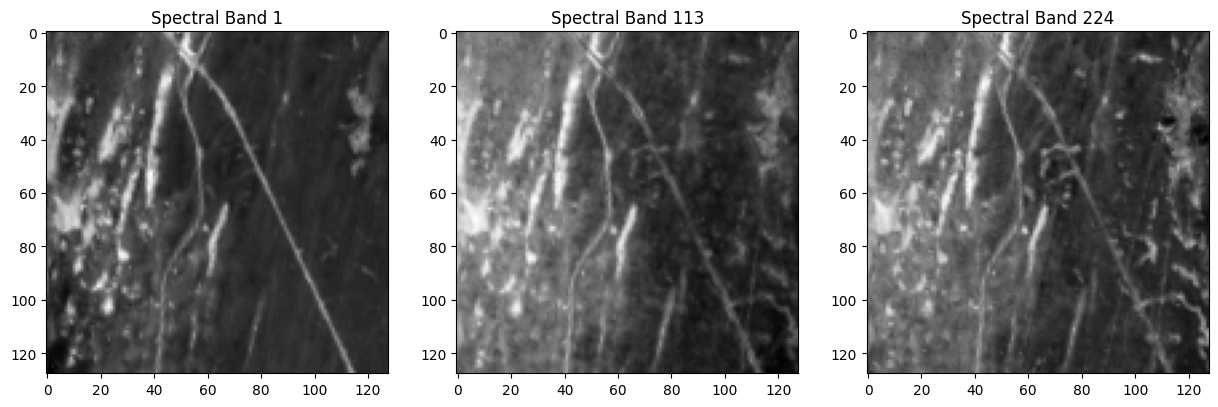

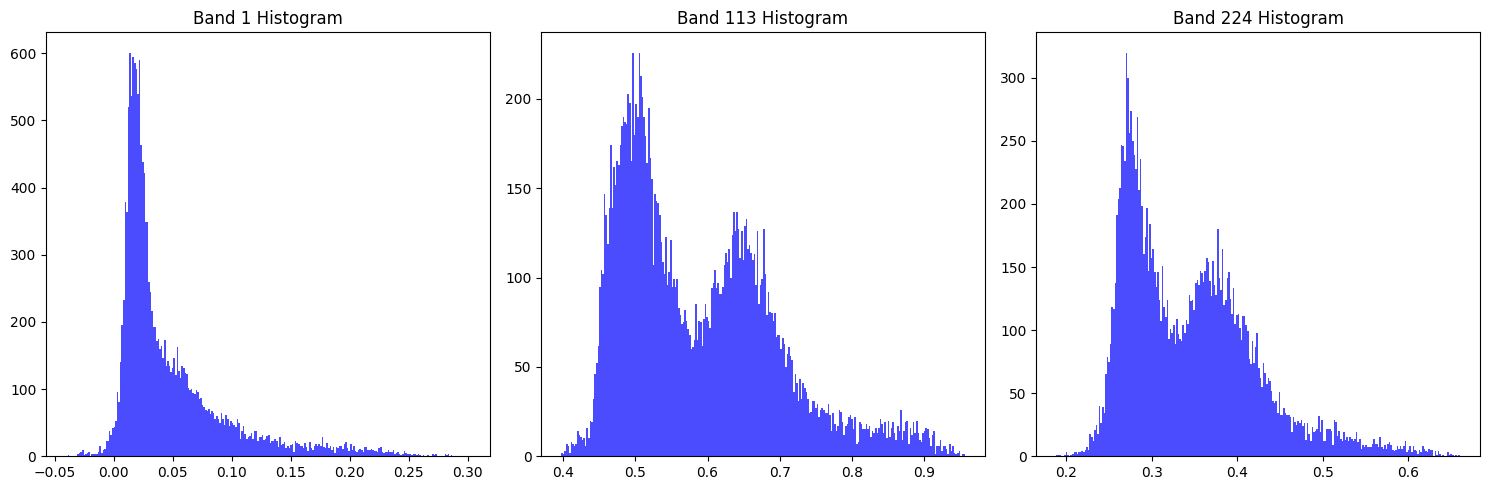

In [195]:
# Fetch the first batch of images
images = test_gen[0]  # If using labels, this would return (images, labels)

def visualize_bands(image, title="Spectral Band"):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    band_indices = [0, image.shape[2] // 2, image.shape[2] - 1]  # First, middle, and last band
    
    for ax, band_index in zip(axes, band_indices):
        ax.imshow(image[:, :, band_index], cmap='gray')
        ax.set_title(f'{title} {band_index + 1}')
    plt.show()

visualize_bands(images[0])

def plot_band_histograms(image, band_indices):
    fig, axes = plt.subplots(1, len(band_indices), figsize=(15, 5))
    for ax, band_index in zip(axes, band_indices):
        ax.hist(image[:, :, band_index].ravel(), bins=256, color='blue', alpha=0.7)
        ax.set_title(f'Band {band_index + 1} Histogram')
    plt.tight_layout()
    plt.show()

# Plot histograms for the first, middle, and last bands
plot_band_histograms(images[0], [0, images[0].shape[2] // 2, images[0].shape[2] - 1])


In [196]:
# take all bands
band_info_df = bands_to_wavelengths(bands)

# Generate a complete 'wavelengths' array for all bands
wavelengths = bands['CW (nm)'].values

# Generate a spectral profile for the entire image or a specific pixel
spectral_profile = generate_spectral_profile(images[0])

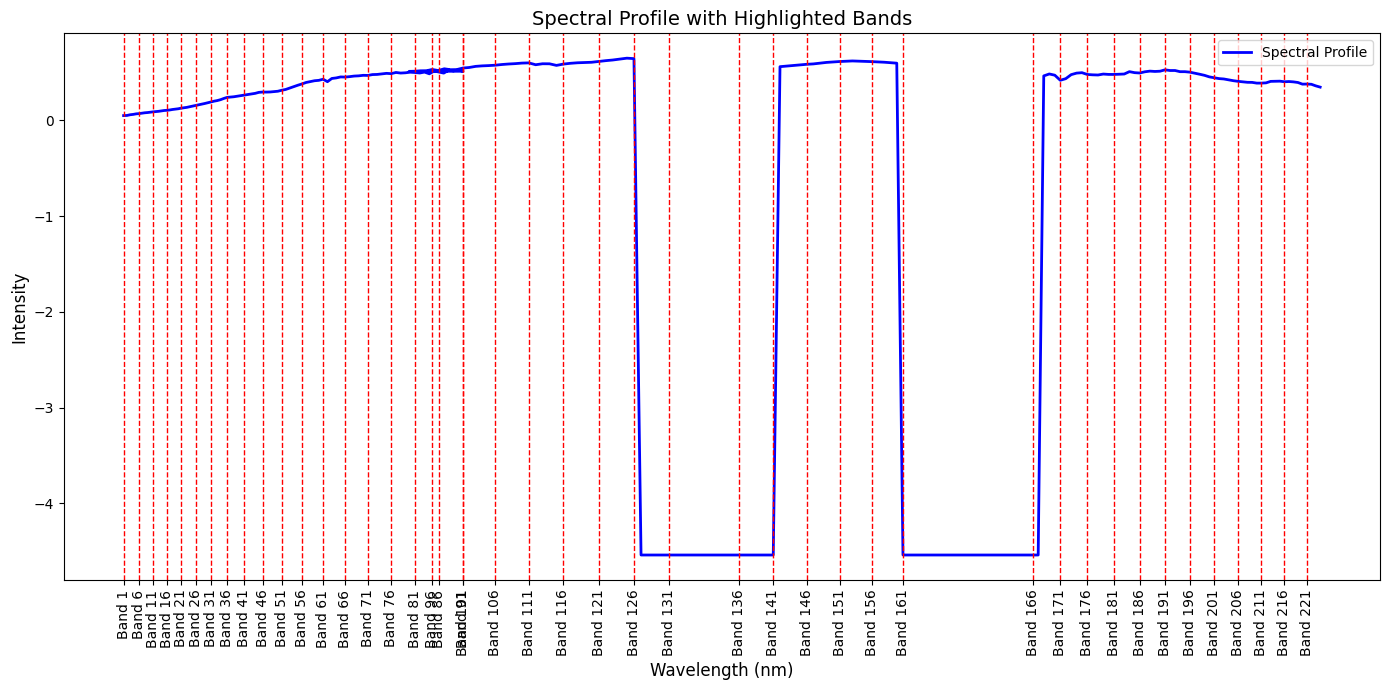

In [202]:
import matplotlib.pyplot as plt


def plot_spectral_profile(band_info_df, wavelengths, spectral_profile):
    plt.figure(figsize=(14, 7))
    
    # Plot the spectral profile
    plt.plot(wavelengths, spectral_profile, label='Spectral Profile', color='blue', linewidth=2)
    
    # Annotate selected bands on the spectral profile
    ymin, ymax = plt.ylim()  # Get the current y-axis limits for placing text labels
    
    # Generate ticks and labels for every 5th band
    ticks = []
    labels = []
    for i, (index, row) in enumerate(band_info_df.iterrows()):
        if i % 5 == 0:  # Select every 5th band for clarity
            plt.axvline(x=row['CW (nm)'], color='red', linestyle='--', linewidth=1)
            ticks.append(row['CW (nm)'])
            labels.append(f"Band {row['BAND #']}")
            

    plt.xticks(ticks, labels, rotation='vertical') 
    plt.xlabel('Wavelength (nm)', fontsize=12)
    plt.ylabel('Intensity', fontsize=12)
    plt.title('Spectral Profile with Highlighted Bands', fontsize=14)
    plt.legend()
    plt.tight_layout() 
    plt.show()

plot_spectral_profile(band_info_df, wavelengths, spectral_profile)

------------------

---------------------------------------------